In [ ]:
import os
import shutil
from pathlib import Path

# Source path in Google Drive
drive_path = Path("/content/drive/MyDrive/data-2.zip")
local_path = Path("/content/data-2.zip")

if drive_path.exists():
    print(f"Found zip in Google Drive at: {drive_path}")
    print("Copying to local workspace to ensure fast access...")
    shutil.copy(drive_path, local_path)
    print("Copy complete!")
else:
    print(f"Could not find '{drive_path.name}' in your Google Drive root folder.")
    print("Please make sure you have uploaded 'data-2.zip' to your Google Drive (My Drive) first.")

Could not find 'data-2.zip' in your Google Drive root folder.
Please make sure you have uploaded 'data-2.zip' to your Google Drive (My Drive) first.


# Satellite Image Classification with Vision Transformers
## Notebook 1: Setup, Data Exploration, Splitting and Zero-Shot CLIP

**Research question:** How well do pre-trained vision transformers (supervised ViT, self-supervised DINOv2, language-supervised CLIP) classify satellite land-cover images, and are their predictions robust or biased by dataset artefacts such as image resolution and colour?

**What this notebook does**
1. Sets up the environment and fixes random seeds
2. Loads the dataset (`cloudy`, `desert`, `green_area`, `water`)
3. Explores it: class balance, image sizes (the 64 vs 256 pixel issue), colours, samples
4. Detects exact and near-duplicate images (to prevent train/test leakage)
5. Makes a leak-free stratified 70/15/15 train/val/test split
6. Extracts CLIP image embeddings and saves them to disk
7. Runs zero-shot CLIP with several prompt templates (chosen on validation only)
8. Evaluates on the test set with accuracy, macro-F1, confusion matrix and bootstrap confidence intervals

**How to use it:** run the cells from top to bottom. Read the markdown above each cell, because the explanations become sentences in your report.

## 0. Setup

**Before you start (Google Colab):**
1. `Runtime -> Change runtime type -> T4 GPU`
2. Upload `data-2.zip` to your Google Drive (e.g. into `My Drive/`)
3. Change `ZIP_PATH` in the config cell below if you put it somewhere else
4. **Easiest alternative:** skip Drive and drag `data-2.zip` into the Files panel (folder icon on the left of Colab). The notebook finds it automatically

In [ ]:
# Run once. Takes about 1 minute on Colab.
!pip install -q transformers scikit-learn matplotlib pandas tqdm

In [ ]:
import os, json, random, hashlib, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ---------------- CONFIG (updated to point to local file) ----------------
ZIP_PATH = "/content/data-2.zip"                 # updated configuration
WORK_DIR = Path("/content/work")                 # temporary workspace (unzipped data)
OUT_DIR  = Path("/content/outputs")              # results, figures, embeddings
SEED     = 42                                    # one seed for the split; vary it later for mean +/- std
# -----------------------------------------------------------------

FIG_DIR = OUT_DIR / "figures"
EMB_DIR = OUT_DIR / "embeddings"
for d in (WORK_DIR, OUT_DIR, FIG_DIR, EMB_DIR):
    d.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
print("Setup OK. Seed =", SEED)

Setup OK. Seed = 42


In [ ]:
# Mount Google Drive (only works inside Colab; harmlessly skipped elsewhere)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running in Colab - skipping Drive mount.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load the data

We unzip the file but **skip the `__MACOSX` folder and `._*` files**. These are hidden junk files created when zipping on a Mac, and they are not images.

In [ ]:
DATA_ROOT = WORK_DIR / "data-2"

def find_zip(preferred):
    """Use ZIP_PATH if it exists, otherwise search the usual places for a data*.zip."""
    if Path(preferred).exists():
        return Path(preferred)
    for folder in ("/content", "/content/drive/MyDrive", "/content/drive/MyDrive/Colab Notebooks"):
        hits = sorted(Path(folder).glob("data*.zip")) if Path(folder).exists() else []
        if hits:
            print("Found zip at:", hits[0])
            return hits[0]
    raise FileNotFoundError(
        "Could not find your zip file.\n"
        "FIX: click the folder icon on the LEFT side of Colab, drag data-2.zip into the Files panel, "
        "wait for the upload to finish, then re-run this cell.")

if not DATA_ROOT.exists():
    with zipfile.ZipFile(find_zip(ZIP_PATH)) as z:
        keep = [m for m in z.namelist()
                if not m.startswith("__MACOSX")
                and "/._" not in m
                and not m.endswith(".DS_Store")]
        z.extractall(WORK_DIR, members=keep)

CLASS_NAMES = sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir())
print("Classes:", CLASS_NAMES)
for c in CLASS_NAMES:
    print(f"  {c:12s} {len(list((DATA_ROOT / c).glob('*.jpg')))} images")

Classes: ['cloudy', 'desert', 'green_area', 'water']
  cloudy       1500 images
  desert       1131 images
  green_area   1500 images
  water        1500 images


### Build a table with one row per image

For each image we record its path, class, width, height, mean colour, a file hash (to find exact duplicates) and a "difference hash" (to find near-duplicates). Having everything in one table (`df`) makes the rest of the project easy.

**dHash in plain words:** shrink the image to 17x16 greyscale, then record whether each pixel is brighter than its right-hand neighbour. Similar-looking images give similar bit patterns.

In [ ]:
def dhash_bits(img, hash_size=16):
    """256-bit difference hash as a numpy array of 0/1."""
    g = img.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten().astype(np.uint8)

rows, hashes = [], []
for label, c in enumerate(CLASS_NAMES):
    for p in tqdm(sorted((DATA_ROOT / c).glob("*.jpg")), desc=c):
        with open(p, "rb") as f:
            md5 = hashlib.md5(f.read()).hexdigest()
        img = Image.open(p).convert("RGB")
        arr = np.asarray(img.resize((32, 32)), dtype=np.float32)
        rows.append(dict(path=str(p), cls=c, label=label,
                         width=img.size[0], height=img.size[1],
                         r=arr[..., 0].mean(), g=arr[..., 1].mean(), b=arr[..., 2].mean(),
                         md5=md5))
        hashes.append(dhash_bits(img))

df = pd.DataFrame(rows)
HASHES = np.stack(hashes)          # shape (N, 256)
df["size"] = df["width"].astype(str) + "x" + df["height"].astype(str)
print("Total images:", len(df))
df.head()

cloudy:   0%|          | 0/1500 [00:00<?, ?it/s]

desert:   0%|          | 0/1131 [00:00<?, ?it/s]

green_area:   0%|          | 0/1500 [00:00<?, ?it/s]

water:   0%|          | 0/1500 [00:00<?, ?it/s]

Total images: 5631


,path,cls,label,width,height,r,g,b,md5,size
0,/content/work/data-2/cloudy/train_10021.jpg,cloudy,0,256,256,212.575195,198.240234,198.542969,9e269e4fb51666455034fc3f809b9cd9,256x256
1,/content/work/data-2/cloudy/train_10043.jpg,cloudy,0,256,256,164.966797,173.197266,166.877930,1d0659849ebd7e324aaf715ace0c78e1,256x256
2,/content/work/data-2/cloudy/train_10070.jpg,cloudy,0,256,256,163.004883,164.283203,147.793945,63efd92e9c9b5404564277555e42eaab,256x256
3,/content/work/data-2/cloudy/train_10081.jpg,cloudy,0,256,256,155.866211,151.975586,140.960938,b74550abd24a684f53a4adef92d2bcc0,256x256
4,/content/work/data-2/cloudy/train_10096.jpg,cloudy,0,256,256,163.200195,145.247070,126.623047,0420b17ce9a822ff66f8c94e0a72b20b,256x256


## 2. Explore the data

### 2.1 Class balance
Report this in your "Dataset" section. A small imbalance (e.g. 1,131 vs 1,500) is why we later report **macro-F1**, not only accuracy.

cls
cloudy        1500
desert        1131
green_area    1500
water         1500
Name: count, dtype: int64


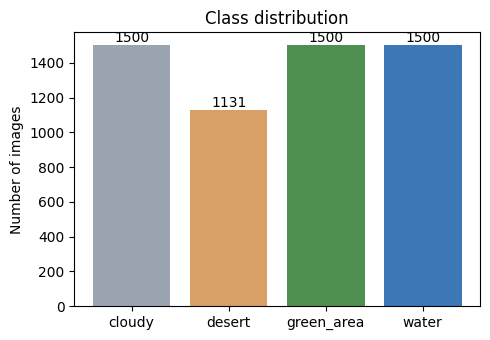

In [ ]:
counts = df["cls"].value_counts().reindex(CLASS_NAMES)
print(counts)

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(counts.index, counts.values, color=["#9aa5b1", "#d9a066", "#4f8f4f", "#3b78b5"])
ax.bar_label(bars)
ax.set_ylabel("Number of images")
ax.set_title("Class distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_class_distribution.png", dpi=150)
plt.show()

### 2.2 Image sizes: the potential shortcut

If image size perfectly predicts the class, a model could "cheat" by detecting resolution or blur instead of looking at the land. We check this now and test it properly in a later notebook.

In [ ]:
size_table = pd.crosstab(df["cls"], df["size"])
print(size_table)

# Does image size alone predict the class? Simple rule: majority class for each size.
size_rule_acc = (df.groupby("size")["cls"].agg(lambda s: s.value_counts().iloc[0]).sum()) / len(df)
print(f"\nAccuracy of a 'model' that only looks at image SIZE: {size_rule_acc:.3f}")
print("Size cannot separate cloudy from desert (both 256x256) or green_area from water (both 64x64),")
print("but it perfectly separates the two PAIRS. So a model can halve the problem without looking at the land.")
print("Chance level is 0.25, so ~0.5 means size alone removes half of the uncertainty.")

size        256x256  64x64
cls                       
cloudy         1500      0
desert         1131      0
green_area        0   1500
water             0   1500

Accuracy of a 'model' that only looks at image SIZE: 0.533
Size cannot separate cloudy from desert (both 256x256) or green_area from water (both 64x64),
but it perfectly separates the two PAIRS. So a model can halve the problem without looking at the land.
Chance level is 0.25, so ~0.5 means size alone removes half of the uncertainty.


### 2.3 Sample images
Always look at your data with your own eyes. Note which classes look similar to each other, since this will help explain errors later.

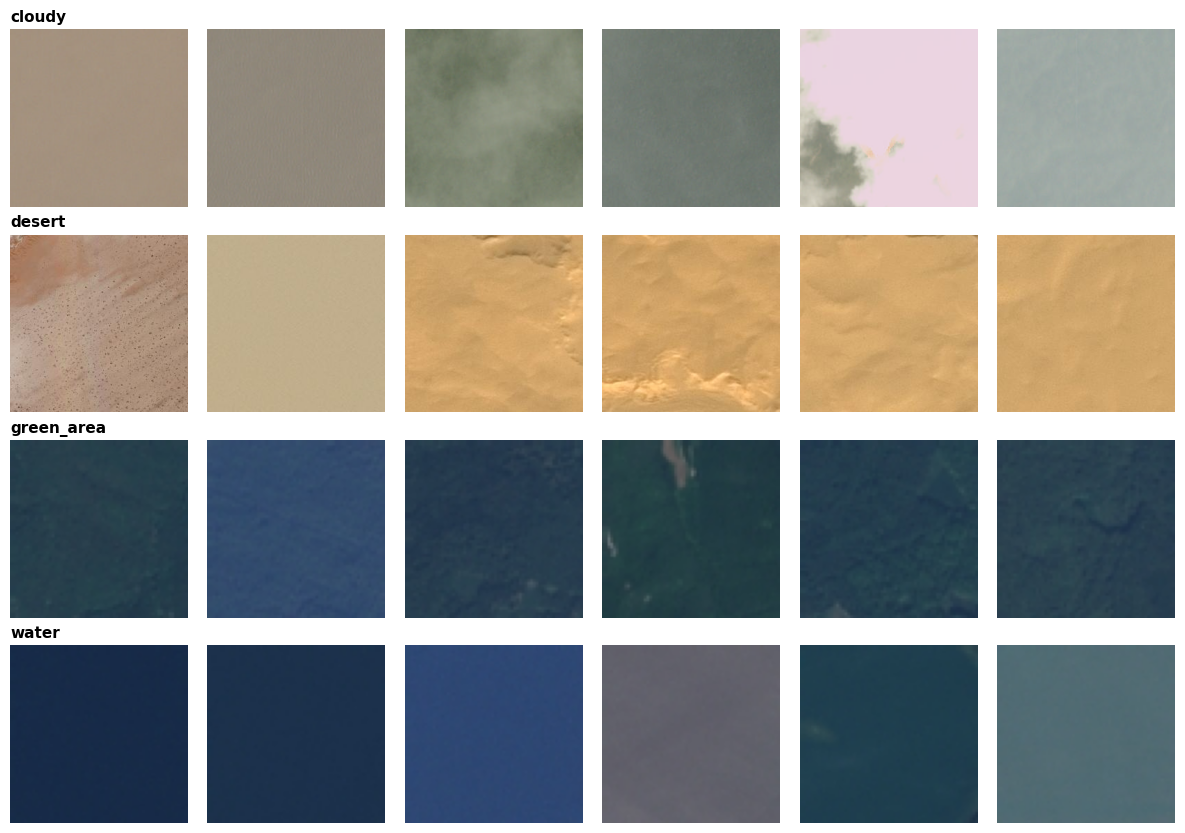

In [ ]:
fig, axes = plt.subplots(len(CLASS_NAMES), 6, figsize=(12, 2.1 * len(CLASS_NAMES)))
rng = np.random.RandomState(SEED)
for i, c in enumerate(CLASS_NAMES):
    sub = df[df["cls"] == c]
    for j, idx in enumerate(rng.choice(sub.index, 6, replace=False)):
        axes[i, j].imshow(Image.open(df.loc[idx, "path"]).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, loc="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_sample_grid.png", dpi=150)
plt.show()

### 2.4 Average colour per class
The classes clearly differ in colour (pale cloud, orange desert, dark green vegetation, dark blue water). We test how far colour alone gets us with a deliberately trivial baseline: three numbers per image (mean R, G, B). Any big model must beat this to justify its cost, and the *gap* tells you what the models learn beyond colour (texture, shapes).

                     r           g           b
cls                                           
cloudy      158.100006  159.199997  148.600006
desert      183.000000  154.899994  127.500000
green_area   39.400002   64.500000   76.000000
water        47.599998   72.300003   88.599998


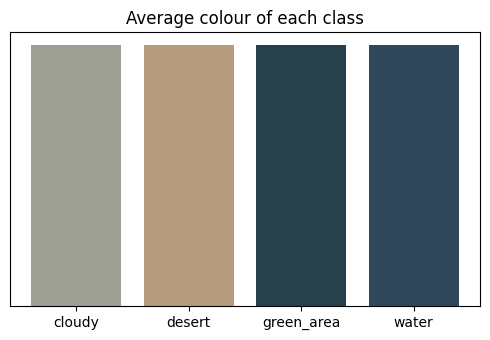


Colour-only baseline (3 numbers per image): accuracy = 0.824


In [ ]:
mean_rgb = df.groupby("cls")[["r", "g", "b"]].mean().reindex(CLASS_NAMES)
print(mean_rgb.round(1))

fig, ax = plt.subplots(figsize=(5, 3.5))
for k, c in enumerate(CLASS_NAMES):
    ax.bar(k, 1, color=(mean_rgb.loc[c].values / 255).clip(0, 1))
ax.set_xticks(range(len(CLASS_NAMES)))
ax.set_xticklabels(CLASS_NAMES)
ax.set_yticks([])
ax.set_title("Average colour of each class")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_mean_colour.png", dpi=150)
plt.show()

# Quick colour-only baseline: logistic regression on just 3 numbers (mean R, G, B)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
Xc = df[["r", "g", "b"]].values
Xtr, Xte, ytr, yte = train_test_split(Xc, df["label"].values, test_size=0.3,
                                      stratify=df["label"], random_state=SEED)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xtr, ytr)
print(f"\nColour-only baseline (3 numbers per image): accuracy = {base.score(Xte, yte):.3f}")

## 3. Duplicate and near-duplicate detection

**Why this matters:** if the same (or almost the same) image is in both train and test, the test score is inflated. This is called **data leakage**, and markers look for it.

We find:
- **Exact duplicates:** identical files (same MD5 hash)
- **Near-duplicates:** dHash bit-difference below a threshold (similar-looking images, e.g. neighbouring tiles of the same scene)

Near-duplicate hits on smooth images (water, sky, desert) can be false alarms, because all flat images look alike. So we use a strict threshold, treat hits as *candidates*, show examples, and group them so they stay together in the same split (safe either way). **In your report, state the threshold you used and how many images were affected.**

In [ ]:
# Exact duplicates
dup_exact = df[df.duplicated("md5", keep=False)]
print("Images involved in exact duplicates:", len(dup_exact))

# Near-duplicates: Hamming distance between 256-bit hashes
NEAR_THRESHOLD = 2           # bits out of 256; lower = stricter. At 10, flat images (water, sky) all
                             # look alike and merge into one giant fake "duplicate" group, so we stay strict.
A = HASHES.astype(np.float32)
B = 1.0 - A
dist = (A.shape[1] - (A @ A.T + B @ B.T)).astype(np.int16)   # Hamming distance matrix
iu = np.triu_indices(len(df), k=1)
close = dist[iu] <= NEAR_THRESHOLD
pairs = np.stack([iu[0][close], iu[1][close]], axis=1)
print(f"Near-duplicate pairs (distance <= {NEAR_THRESHOLD}): {len(pairs)}")

same_cls = (df["label"].values[pairs[:, 0]] == df["label"].values[pairs[:, 1]])
print("  within the same class:", int(same_cls.sum()))
print("  ACROSS different classes (label noise, or very flat look-alike images):", int((~same_cls).sum()))

# Exact duplicates that carry DIFFERENT labels are definite label noise
mixed = df[df.duplicated("md5", keep=False)].groupby("md5")["cls"].nunique()
print("Exact-duplicate groups with conflicting labels:", int((mixed > 1).sum()))
del dist

Images involved in exact duplicates: 78
Near-duplicate pairs (distance <= 2): 77
  within the same class: 56
  ACROSS different classes (label noise, or very flat look-alike images): 21
Exact-duplicate groups with conflicting labels: 0


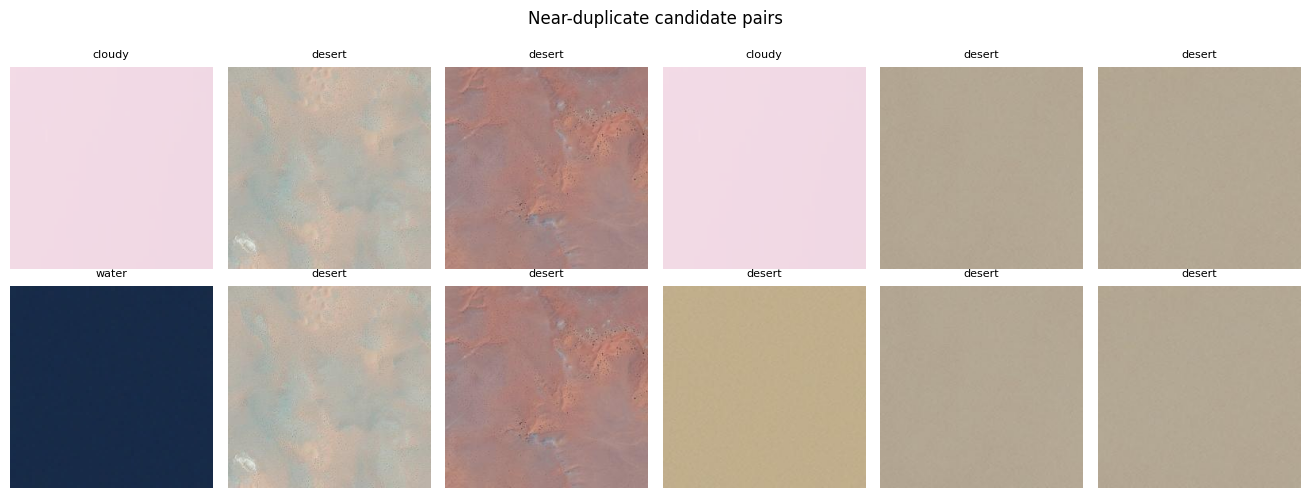

In [ ]:
# Look at a few near-duplicate pairs with your own eyes
show = pairs[np.random.RandomState(SEED).permutation(len(pairs))[:6]] if len(pairs) else []
if len(show):
    fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 5))
    axes = np.atleast_2d(axes).reshape(2, -1)
    for k, (i, j) in enumerate(show):
        for r, idx in enumerate((i, j)):
            axes[r, k].imshow(Image.open(df.loc[idx, "path"]).convert("RGB"))
            axes[r, k].set_title(df.loc[idx, "cls"], fontsize=8)
            axes[r, k].axis("off")
    plt.suptitle("Near-duplicate candidate pairs", y=1.0)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "04_near_duplicates.png", dpi=150)
    plt.show()
else:
    print("No near-duplicate pairs found at this threshold.")

## 4. Leak-free train / validation / test split

**Plan**
1. Link every pair of exact or near-duplicate images into a **group** (connected components).
2. Split **groups** (not single images) 70 / 15 / 15, stratified by class, so duplicates can never end up on both sides.
3. Save the split to a CSV. **Use the same split in every experiment** so models are compared fairly.
4. **Never tune anything on the test set.** Choose prompts and hyperparameters on validation only.

In [ ]:
# Union-find to build duplicate groups
parent = list(range(len(df)))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

for i, j in pairs:
    union(int(i), int(j))
for _, idxs in df.groupby("md5").groups.items():      # exact duplicates
    idxs = list(idxs)
    for k in idxs[1:]:
        union(idxs[0], k)

df["group"] = [find(i) for i in range(len(df))]
groups = df.groupby("group").agg(label=("label", lambda s: s.value_counts().index[0]),
                                 n=("label", "size")).reset_index()
print(f"{len(df)} images -> {len(groups)} groups "
      f"({(groups['n'] > 1).sum()} groups contain more than one image)")

# Split groups, stratified by each group's majority label
g_train, g_tmp = train_test_split(groups, test_size=0.30, stratify=groups["label"], random_state=SEED)
g_val, g_test = train_test_split(g_tmp, test_size=0.50, stratify=g_tmp["label"], random_state=SEED)

split_of = {}
for name, g in (("train", g_train), ("val", g_val), ("test", g_test)):
    for gid in g["group"]:
        split_of[gid] = name
df["split"] = df["group"].map(split_of)

print(pd.crosstab(df["cls"], df["split"])[["train", "val", "test"]])
print("\nTotal per split:", df["split"].value_counts().to_dict())

df.drop(columns=["md5"]).to_csv(OUT_DIR / "split.csv", index=False)
print("Saved split ->", OUT_DIR / "split.csv")

5631 images -> 5574 groups (40 groups contain more than one image)
split       train  val  test
cls                         
cloudy       1050  225   225
desert        788  173   170
green_area   1050  225   225
water        1054  223   223

Total per split: {'train': 3942, 'val': 846, 'test': 843}
Saved split -> /content/outputs/split.csv


## 5. CLIP: load the model and extract image embeddings

**Embedding** = a list of numbers (512 for this CLIP) that summarises an image's meaning.
We compute embeddings **once** for all images, save them to disk, and reuse them for zero-shot now and the **linear probe in the next notebook**.

**Pre-processing note:** CLIP's processor resizes each image to 224x224 and normalises it. The 64x64 images (green_area, water) are therefore **upscaled 3.5x and look blurry**. Mention this in your pre-processing section, because it is also part of the possible size shortcut.

In [ ]:
import torch
from transformers import CLIPModel, CLIPProcessor

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cpu":
    print("WARNING: no GPU found. Use Runtime -> Change runtime type -> T4 GPU. CPU will be slow.")

CLIP_NAME = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(CLIP_NAME).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_NAME)
print("Loaded", CLIP_NAME, "| parameters: %.0fM" % (sum(p.numel() for p in clip_model.parameters()) / 1e6))

Device: cuda


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Loaded openai/clip-vit-base-patch32 | parameters: 151M


In [ ]:
def as_tensor(x):
    """Different transformers versions return a tensor or an output object."""
    return x if isinstance(x, torch.Tensor) else x.pooler_output

@torch.no_grad()
def extract_image_embeddings(paths, model, processor, batch_size=64):
    feats = []
    for i in tqdm(range(0, len(paths), batch_size), desc="Embedding images"):
        imgs = [Image.open(p).convert("RGB") for p in paths[i:i + batch_size]]
        inputs = processor(images=imgs, return_tensors="pt").to(DEVICE)
        f = as_tensor(model.get_image_features(**inputs))
        feats.append(torch.nn.functional.normalize(f, dim=-1).cpu())
    return torch.cat(feats).numpy()

emb_file = EMB_DIR / "clip_b32_images.npy"
if emb_file.exists():
    IMG_EMB = np.load(emb_file)
    print("Loaded cached embeddings:", IMG_EMB.shape)
else:
    IMG_EMB = extract_image_embeddings(df["path"].tolist(), clip_model, clip_proc)
    np.save(emb_file, IMG_EMB)
    print("Saved embeddings:", IMG_EMB.shape)

assert IMG_EMB.shape[0] == len(df)

Embedding images:   0%|          | 0/88 [00:00<?, ?it/s]

Saved embeddings: (5631, 512)


## 6. Zero-shot CLIP

**Zero-shot** = no training at all. We write a text description for each class, CLIP embeds the text, and each image is assigned to the class whose text is most similar.

**Prompt engineering is an experiment.** We try several templates and a few class wordings, and **choose the best one on the validation set only**.

In [ ]:
# Plain class names vs. richer descriptions (compare them: this is a result!)
CLASS_TEXT_PLAIN = {"cloudy": "clouds", "desert": "desert",
                    "green_area": "green area", "water": "water"}
CLASS_TEXT_RICH  = {"cloudy": "clouds covering the ground",
                    "desert": "desert with sand and bare rock",
                    "green_area": "green vegetation, forest or farmland",
                    "water": "water such as sea, lake or river"}

TEMPLATES = {
    "plain":      "{}",
    "photo":      "a photo of {}.",
    "satellite":  "a satellite photo of {}.",
    "aerial":     "an aerial image of {}.",
    "from_space": "a satellite image taken from space showing {}.",
}

@torch.no_grad()
def text_embeddings(template, class_text):
    prompts = [template.format(class_text[c]) for c in CLASS_NAMES]
    inputs = clip_proc(text=prompts, return_tensors="pt", padding=True).to(DEVICE)
    f = as_tensor(clip_model.get_text_features(**inputs))
    return torch.nn.functional.normalize(f, dim=-1).cpu().numpy()      # (4, 512)

def predict_zero_shot(txt_emb, idx):
    sims = IMG_EMB[idx] @ txt_emb.T                                     # cosine similarity
    return sims.argmax(axis=1)

val_idx  = np.where(df["split"] == "val")[0]
test_idx = np.where(df["split"] == "test")[0]
y = df["label"].values

# Evaluate every (class wording, template) combination on VALIDATION
results_val = []
text_bank = {}
for wording, ct in (("plain_names", CLASS_TEXT_PLAIN), ("rich_names", CLASS_TEXT_RICH)):
    for tname, t in TEMPLATES.items():
        te = text_embeddings(t, ct)
        text_bank[(wording, tname)] = te
        pred = predict_zero_shot(te, val_idx)
        results_val.append(dict(wording=wording, template=tname,
                                val_acc=accuracy_score(y[val_idx], pred),
                                val_macro_f1=f1_score(y[val_idx], pred, average="macro")))

# Prompt ensemble: average the text embeddings of all templates (a common CLIP trick)
for wording in ("plain_names", "rich_names"):
    ens = np.mean([text_bank[(wording, t)] for t in TEMPLATES], axis=0)
    ens /= np.linalg.norm(ens, axis=1, keepdims=True)
    text_bank[(wording, "ENSEMBLE")] = ens
    pred = predict_zero_shot(ens, val_idx)
    results_val.append(dict(wording=wording, template="ENSEMBLE",
                            val_acc=accuracy_score(y[val_idx], pred),
                            val_macro_f1=f1_score(y[val_idx], pred, average="macro")))

val_table = pd.DataFrame(results_val).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
val_table.round(4)

,wording,template,val_acc,val_macro_f1
0,rich_names,from_space,0.7305,0.7299
1,plain_names,from_space,0.7222,0.7155
2,rich_names,plain,0.7199,0.7143
3,rich_names,satellite,0.7175,0.7101
4,plain_names,satellite,0.7069,0.7052
5,rich_names,ENSEMBLE,0.7092,0.7024
6,rich_names,aerial,0.6466,0.6550
7,rich_names,photo,0.6064,0.5810
8,plain_names,ENSEMBLE,0.5827,0.5734
9,plain_names,photo,0.5449,0.5318


Best prompt chosen ON VALIDATION: ('rich_names', 'from_space')


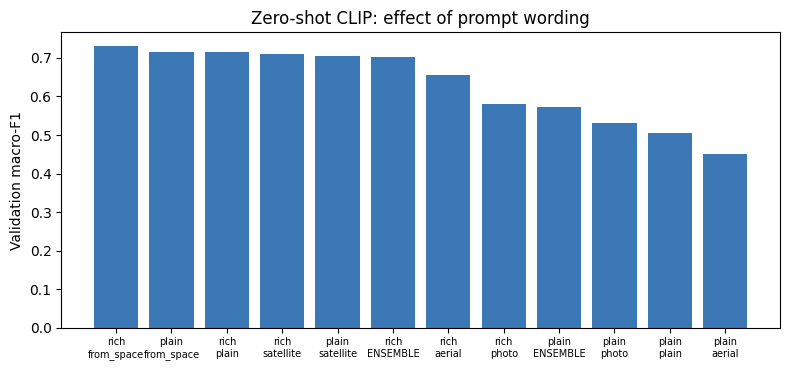

In [ ]:
best = val_table.iloc[0]
BEST_KEY = (best["wording"], best["template"])
print("Best prompt chosen ON VALIDATION:", BEST_KEY)

fig, ax = plt.subplots(figsize=(8, 3.8))
labels = [f"{w.split('_')[0]}\n{t}" for w, t in zip(val_table["wording"], val_table["template"])]
ax.bar(range(len(val_table)), val_table["val_macro_f1"], color="#3b78b5")
ax.set_xticks(range(len(val_table)))
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Validation macro-F1")
ax.set_title("Zero-shot CLIP: effect of prompt wording")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_prompt_comparison.png", dpi=150)
plt.show()

## 7. Final zero-shot evaluation on the TEST set

We evaluate **once**, with the prompt chosen on validation.

**Metrics**
- **Accuracy:** % correct
- **Macro-F1:** F1 averaged over classes (treats each class equally, which matters because the classes are imbalanced)
- **95% bootstrap confidence interval:** we resample the test set 1,000 times to see how much the score could vary by chance. If two models' intervals overlap heavily, you cannot claim one is better.

In [ ]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    n = len(y_true)
    scores = [metric(y_true[ix], y_pred[ix]) for ix in (rng.randint(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])

macro_f1 = lambda a, b: f1_score(a, b, average="macro")

pred_test = predict_zero_shot(text_bank[BEST_KEY], test_idx)
y_test = y[test_idx]

acc = accuracy_score(y_test, pred_test)
f1m = macro_f1(y_test, pred_test)
acc_ci = bootstrap_ci(y_test, pred_test, accuracy_score)
f1_ci = bootstrap_ci(y_test, pred_test, macro_f1)

print(f"Zero-shot CLIP ViT-B/32 on TEST ({len(test_idx)} images), prompt = {BEST_KEY}")
print(f"  Accuracy : {acc:.4f}  (95% CI {acc_ci[0]:.4f} - {acc_ci[1]:.4f})")
print(f"  Macro-F1 : {f1m:.4f}  (95% CI {f1_ci[0]:.4f} - {f1_ci[1]:.4f})")
print()
print(classification_report(y_test, pred_test, target_names=CLASS_NAMES, digits=3))

Zero-shot CLIP ViT-B/32 on TEST (843 images), prompt = ('rich_names', 'from_space')
  Accuracy : 0.7461  (95% CI 0.7153 - 0.7758)
  Macro-F1 : 0.7482  (95% CI 0.7157 - 0.7765)

              precision    recall  f1-score   support

      cloudy      0.664     0.729     0.695       225
      desert      0.695     0.994     0.818       170
  green_area      0.965     0.609     0.747       225
       water      0.754     0.713     0.733       223

    accuracy                          0.746       843
   macro avg      0.769     0.761     0.748       843
weighted avg      0.774     0.746     0.744       843



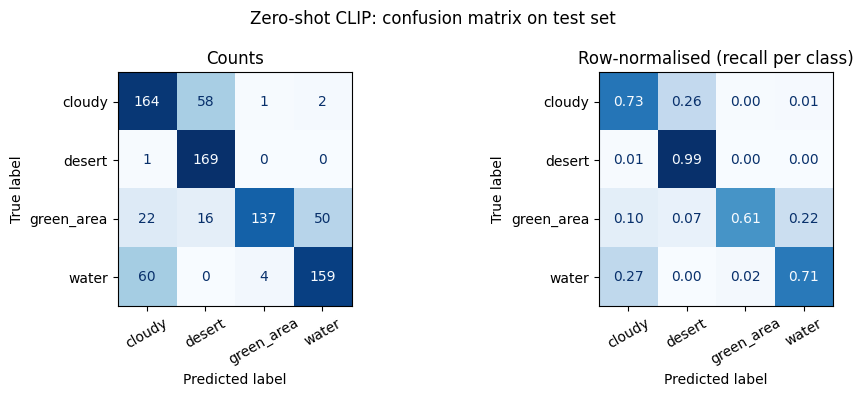

In [ ]:
cm = confusion_matrix(y_test, pred_test)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=30)
axes[0].set_title("Counts")
ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=CLASS_NAMES).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=30, values_format=".2f")
axes[1].set_title("Row-normalised (recall per class)")
plt.suptitle("Zero-shot CLIP: confusion matrix on test set")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_zero_shot_confusion.png", dpi=150)
plt.show()

214 wrong predictions out of 843


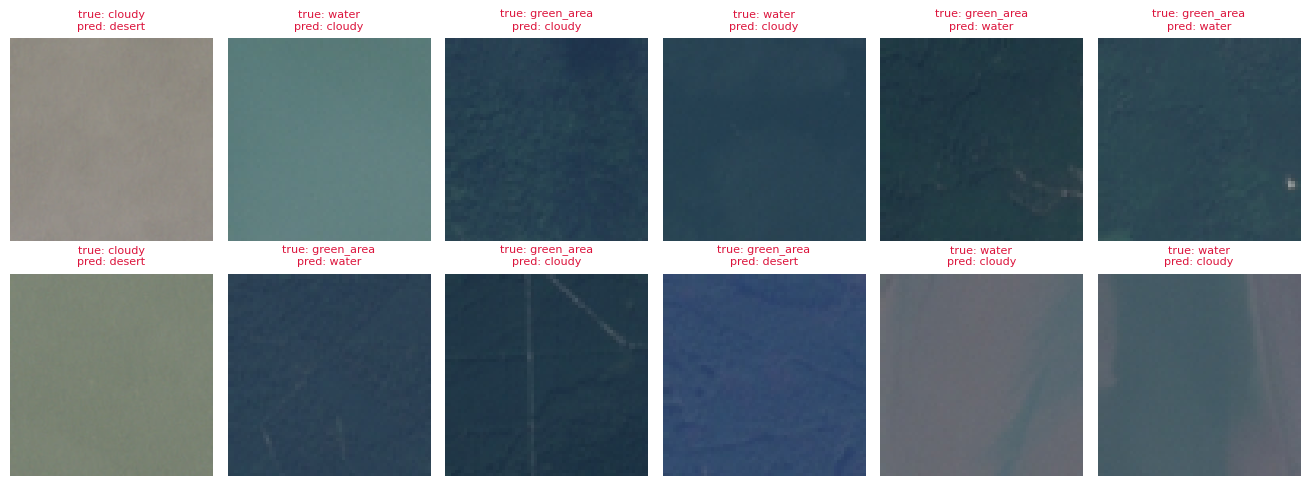

In [ ]:
# Look at mistakes: you will categorise 30-50 of these by hand later (lighting, mixed scene, label noise...)
wrong = test_idx[pred_test != y_test]
print(f"{len(wrong)} wrong predictions out of {len(test_idx)}")

if len(wrong):
    pick = np.random.RandomState(SEED).choice(wrong, min(12, len(wrong)), replace=False)
    cols = 6
    rows_n = int(np.ceil(len(pick) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(2.2 * cols, 2.5 * rows_n))
    axes = np.atleast_1d(axes).flatten()
    for ax in axes:
        ax.axis("off")
    for ax, idx in zip(axes, pick):
        pred_label = CLASS_NAMES[predict_zero_shot(text_bank[BEST_KEY], [idx])[0]]
        ax.imshow(Image.open(df.loc[idx, "path"]).convert("RGB"))
        ax.set_title(f"true: {df.loc[idx, 'cls']}\npred: {pred_label}", fontsize=8, color="crimson")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "07_zero_shot_errors.png", dpi=150)
    plt.show()

## 8. Save results

Store every result in a JSON file as you go. When you write the report, you copy the numbers from here, so nothing gets lost or mistyped.

In [ ]:
results = {
    "zero_shot_clip_b32": {
        "prompt": list(BEST_KEY),
        "test_accuracy": float(acc), "test_accuracy_ci95": [float(x) for x in acc_ci],
        "test_macro_f1": float(f1m), "test_macro_f1_ci95": [float(x) for x in f1_ci],
        "n_test": int(len(test_idx)),
    },
    "colour_only_baseline_accuracy": float(base.score(Xte, yte)),
    "size_only_rule_accuracy": float(size_rule_acc),
    "split_counts": df["split"].value_counts().to_dict(),
    "seed": SEED,
}
val_table.to_csv(OUT_DIR / "zero_shot_prompt_validation.csv", index=False)
with open(OUT_DIR / "results_notebook1.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps(results, indent=2))

# Zip everything so you can download it from Colab
import shutil
shutil.make_archive("/content/notebook1_outputs", "zip", OUT_DIR)
print("\nCreated /content/notebook1_outputs.zip (download it from the Files panel on the left).")

{
  "zero_shot_clip_b32": {
    "prompt": [
      "rich_names",
      "from_space"
    ],
    "test_accuracy": 0.7461447212336892,
    "test_accuracy_ci95": [
      0.7152728351126928,
      0.7758303677342823
    ],
    "test_macro_f1": 0.7481575226855253,
    "test_macro_f1_ci95": [
      0.7157463898027113,
      0.7765340535032951
    ],
    "n_test": 843
  },
  "colour_only_baseline_accuracy": 0.8242603550295858,
  "size_only_rule_accuracy": 0.5327650506126798,
  "split_counts": {
    "train": 3942,
    "val": 846,
    "test": 843
  },
  "seed": 42
}

Created /content/notebook1_outputs.zip (download it from the Files panel on the left).
